# Header

In [2]:
source('functions.R')


Attaching package: ‘dplyr’


The following object is masked from ‘package:gridExtra’:

    combine


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers




In [1]:
library(Seurat)
library(patchwork)
library(ggplot2)

Loading required package: SeuratObject

Loading required package: sp


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t




In [3]:
setwd('../')

# Sample PCA

In [4]:
pb = qs::qread('data/06_pb/pb_donor.qs')

pb

An object of class Seurat 
28202 features across 55 samples within 5 assays 
Active assay: RNA (27879 features, 0 variable features)
 3 layers present: counts, data, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT

In [5]:
head(pb@meta.data)

,orig.ident,dataset_name
,<chr>,<chr>
Pool137-10,Pool137-10,Pool137-10
Pool137-11,Pool137-11,Pool137-11
Pool137-12,Pool137-12,Pool137-12
Pool137-14,Pool137-14,Pool137-14
Pool137-15,Pool137-15,Pool137-15
Pool137-16,Pool137-16,Pool137-16


In [6]:
meta = read.csv('data/01_meta/meta_pt.csv', row.names = 2)
meta

,sampleid,batch,viability_pct,group,race,age,diabetes,obesity,race_stage
,<chr>,<int>,<int>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
Pool137_7,9-D,1,95,DCIS,NHW,37.0,N,Y,NHW-DCIS
Pool137_12,30-D,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
Pool137_18,36-D,1,93,DCIS,NHB,39.0,N,Y,NHB-DCIS
Pool137_20,119-D,1,95,DCIS,NHB,80.0,N,Y,NHB-DCIS
Pool137_24,28-D,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
Pool137_27,53-D,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
Pool137_30,77-D,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
Pool138_6,31-D,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
Pool137_6,6-H,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [7]:
library(dplyr)
library(tibble)

pb@meta.data$dataset_name <- gsub("-", "_", pb@meta.data$dataset_name)


pb@meta.data <- pb@meta.data %>%
  rownames_to_column("cell_id") %>%
  left_join(
    meta %>%
      rownames_to_column("dataset_name"),
    by = "dataset_name"
  ) %>%
  column_to_rownames("cell_id")

In [8]:
pb@meta.data$batch <- ifelse(
  startsWith(as.character(pb@meta.data$dataset_name), "Pool137"),
  "Batch 1",
  "Batch 2"
)

In [9]:
pb@meta.data$recruitment <- ifelse(
  pb@meta.data$group == "HRL",
  "B-PREP",
  "Project SHARE"
)

In [10]:
head(pb@meta.data)

,orig.ident,dataset_name,sampleid,batch,viability_pct,group,race,age,diabetes,obesity,race_stage,recruitment
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>
Pool137-10,Pool137-10,Pool137_10,1-H,Batch 1,88,HRL,NHW,62.3,N,N,NHW-HRL,B-PREP
Pool137-11,Pool137-11,Pool137_11,19-I,Batch 1,92,BC,NHW,48.0,N,N,NHW-BC,Project SHARE
Pool137-12,Pool137-12,Pool137_12,30-D,Batch 1,92,DCIS,NHW,78.0,N,N,NHW-DCIS,Project SHARE
Pool137-14,Pool137-14,Pool137_14,43-H,Batch 1,91,HRL,NHW,42.5,N,Y,NHW-HRL,B-PREP
Pool137-15,Pool137-15,Pool137_15,45-I,Batch 1,91,BC,NHW,67.0,N,N,NHW-BC,Project SHARE
Pool137-16,Pool137-16,Pool137_16,56-I,Batch 1,92,BC,NHB,60.0,N,Y,NHB-BC,Project SHARE


In [11]:
library(Seurat)

DefaultAssay(pb) <- "RNA"

# 1. Normalize from counts (pseudobulk = summed counts; log-normalize is fine,
#    or use CPM/edgeR-style if you prefer — but re-normalize, don't trust an
#    inherited `data` layer from the single-cell object)
pb <- NormalizeData(pb)

# 2. You MUST pick variable features — PCA uses these by default
pb <- FindVariableFeatures(pb, selection.method = "vst", nfeatures = 2000)

# 3. Scale (center + scale the variable genes)
pb <- ScaleData(pb)

# 4. PCA — cap npcs at n_samples - 1
pb <- RunPCA(pb, npcs = min(50, ncol(pb) - 1))

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
“Different features in new layer data than already exists for scale.data”
Warning message in svd.function(A = t(x = object), nv = npcs, ...):
“You're computing too large a percentage of total singular values, use a standard svd instead.”
PC_ 1 
Positive:  STRN3, SNX13, VTI1A, ARL15, ZNF407, MCU, VPS13B, TMEM131, XIST, RUNX1 
	   WDR7, FER, CERS6, TRPS1, CLASP1, RAD51B, ATP11C, NLK, PHF21A, AHCYL2 
	   SLC9A9, EXOC6B, XRCC4, PELI2, DPYD, ZDHHC20, BTRC, DIP2B, BAZ2B, GPD2 
Negative:  AL138963.4, CTSW, CCL5, CD8B, GZMK, TRBV28, IGLV1-40, LAG3, TRBV12-4, TRBV11-2 
	   TRBV3-1, IGKC, TRBV5-6, TRAV14DV4, KANSL1-AS1, IGHA1, IGKV1-5, HOPX, TRBV11-3, TRAV38-1 
	   TRBV4-2, CD8A, TRBV4-1, CST7, AC016405.3, GZMA, TRAV12-2, GNLY, COL6A2, DUSP2 
PC_ 2 
Positive:  THEMIS, IL7R, LINC02725, MIR31HG, KLRG1, CAMK4, LINC01934, FAM153A, LINC00612, RASGRF2 
	   IFNG-AS1, LINC02100, ABC

In [12]:
pb$race        <- factor(pb$race,        levels = c("NHW", "NHB"))
pb$group       <- factor(pb$group,       levels = c("HRL", "DCIS", "BC"))
pb$recruitment <- factor(pb$recruitment, levels = c("B-PREP", "Project SHARE"))
pb$batch       <- factor(pb$batch,       levels = c("Batch 1", "Batch 2"))
pb$diabetes    <- factor(pb$diabetes,    levels = c("N", "Y"))
pb$obesity     <- factor(pb$obesity,     levels = c("N", "Y"))

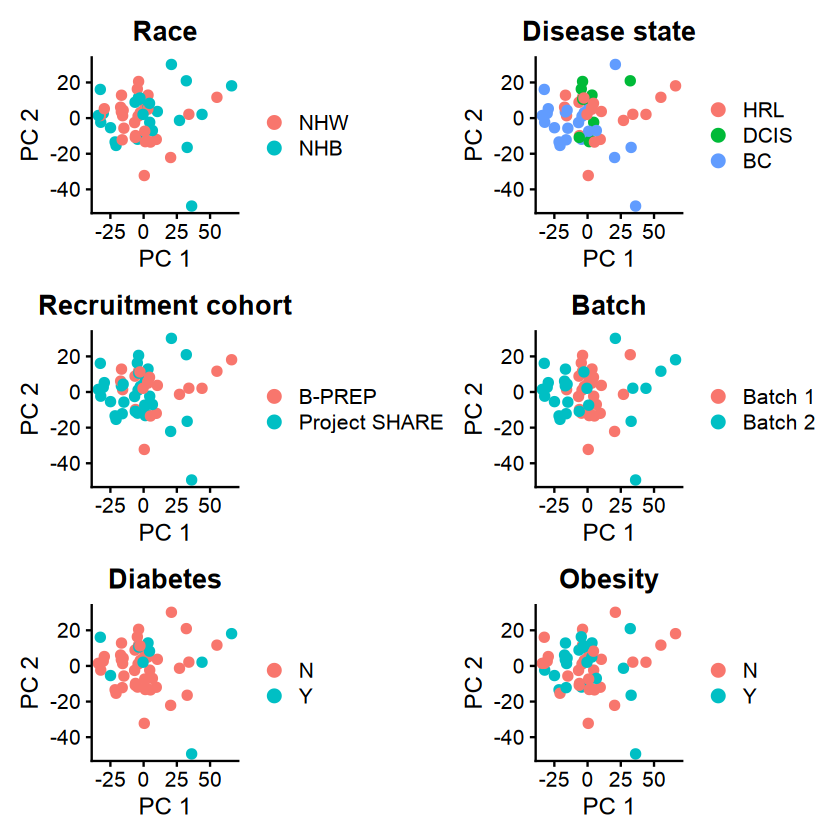

In [17]:
vars   <- c("race", "group", "recruitment", "batch", "diabetes", "obesity")
titles <- c("Race", "Disease state", "Recruitment cohort", "Batch", "Diabetes", "Obesity")

plots <- Map(function(v, t) {
  DimPlot(pb, reduction = "pca", group.by = v, pt.size = 2) +
    ggtitle(t) +
    xlab("PC 1") + ylab("PC 2")
}, vars, titles)

p <- wrap_plots(plots, ncol = 2)
print(p)
ggsave("plots/Rebuttal/sample_pca.png", p,
       width = 8, height = 10, dpi = 300)